# Задача классификации
Датасет **Titanic-Dataset**: 
- целевая переменная - **Survived** 


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import kagglehub
from kagglehub import KaggleDatasetAdapter

%matplotlib inline
sns.set_theme(style="darkgrid")

file_path = "Titanic-Dataset.csv"

# Load the latest version
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "yasserh/titanic-dataset",
  file_path,
  # Provide any additional arguments like 
  # sql_query or pandas_kwargs. See the 
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)


pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

print(df.shape)
print(df.head())
print(df["Survived"].describe())

print("Количество пропусков в каждом столбце:")
display(df.isna().sum().to_frame(name="missing_values").T)
print(f"Количество полных дубликатов строк: {df.duplicated().sum()}")

(891, 12)
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN    

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
missing_values,0,0,0,0,0,177,0,0,0,0,687,2


Количество полных дубликатов строк: 0


**Объем и целостность данных:** Датасет содержит 891 объект и 12 столбцов (числовые: `Age`, `Fare`, `SibSp`, `Parch`; порядковые/бинарные: `Survived`, `Pclass`; строковые/категориальные: `Name`, `Sex`, `Ticket`, `Cabin`, `Embarked`). Полных дубликатов строк нет. Много пропусков номера кабины, меньше - возраст и порт посадки

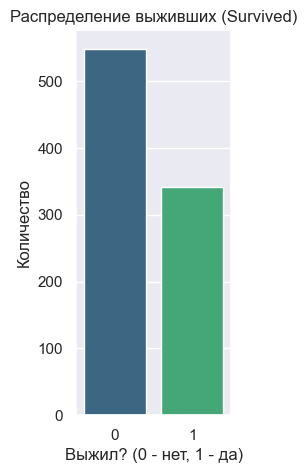

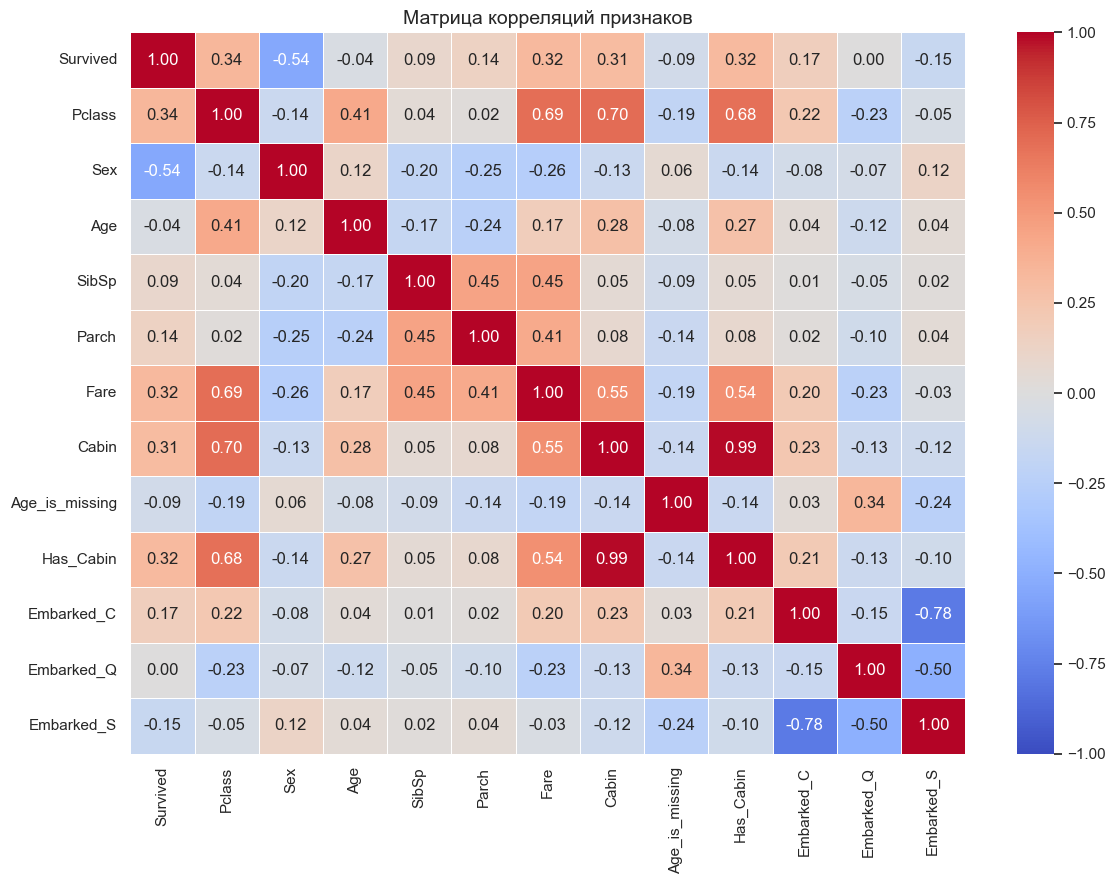

In [14]:
plt.figure(figsize=(2, 5))
ax = sns.countplot(data=df, x="Survived", hue="Survived", palette="viridis", legend=False)
plt.title("Распределение выживших (Survived)")
plt.xlabel("Выжил? (0 - нет, 1 - да)")
plt.ylabel("Количество")
plt.show()

    
def extract_deterministic_features(df_in):
    d = df_in.copy()
    
    d['Age_is_missing'] = d['Age'].isna().astype(int)
    d['Has_Cabin'] = d['Cabin'].notna().astype(int)
    
    cabin_map = {'A': 8, 'B': 7, 'C': 6, 'D': 5, 'E': 4, 'F': 3, 'G': 2, 'T': 1}
    d['Cabin'] = d['Cabin'].str[0].map(cabin_map).fillna(0).astype(int)
    
    d['Sex'] = d['Sex'].map({'male': 1, 'female': 0})
    d['Pclass'] = d['Pclass'].map({1: 3, 2: 2, 3: 1})
    return d

df_filled = df.copy()
df_filled = extract_deterministic_features(df_filled)

most_freq_port = df_filled['Embarked'].mode()[0]
df_filled['Embarked'] = df_filled['Embarked'].fillna(most_freq_port)
df_filled = pd.get_dummies(df_filled, columns=['Embarked'], drop_first=False, dtype=int)

df_filled = df_filled.drop(columns=["Name", "Ticket", "PassengerId"])

df_filled['Age'] = df_filled['Age'].fillna(df_filled.groupby(['Pclass', 'Sex'])['Age'].transform('median'))

corr_matrix = df_filled.corr(method='spearman', numeric_only=True)
plt.figure(figsize=(12, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1, vmax=1,
    linewidths=0.5
)

plt.title("Матрица корреляций признаков", fontsize=14)
plt.tight_layout()
plt.show()

### Выводы по первичному анализу данных:
1. **Баланс классов:** Целевая переменная `Survived` несбалансирована — выжило около 38.4% пассажиров (класс `1`), погибло 61.6% (класс `0`). Поэтому при разбиении выборки необходима стратификация.
2. **Неинформативные признаки:** Столбцы `PassengerId`, `Name` и `Ticket` являются уникальными идентификаторами пассажиров. Их прямое использование приведет к бессмысленному запоминанию объектов моделью, поэтому при обучении они удаляются.
3. **Корреляционный анализ:** Сильной корреляции (>= 0.7) с целевой переменной `Survived` ни у одного признака не наблюдается. Наиболее сильная связь с выживаемостью наблюдается у признаков `Sex` (-0.54 - женщины выживали значительно чаще мужчин), `Pclass` (0.34), `Fare` (0.32) и `Cabin` (0.31). Между уровнем палубы `Cabin` и синтетическим бинарным флагом `Has_Cabin` обнаружена мультиколлинеарность (0.99), поэтому избыточный признак `Has_Cabin` исключен из итогового пайплайна.

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix


RANDOM_STATE = 42

class GroupMedianAgeImputer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        self.group_medians_ = X.groupby(['Pclass', 'Sex'])['Age'].median()
        self.global_median_ = X['Age'].median()
        return self

    def transform(self, X):
        X_out = X.copy()
        mapped_age = (
            X_out.set_index(['Pclass', 'Sex'])
            .index.map(self.group_medians_)
            .to_series(index=X_out.index)
        )
        X_out['Age'] = X_out['Age'].fillna(mapped_age).fillna(self.global_median_)
        return X_out

numeric_features = ['Age', 'Fare', 'SibSp', 'Parch', 'Pclass', 'Cabin', 'Sex', 'Age_is_missing']
categorical_features = ['Embarked']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

column_preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='drop'
)

preprocessor = Pipeline(steps=[
    ('feature_extraction', FunctionTransformer(extract_deterministic_features)),
    ('age_group_imputer', GroupMedianAgeImputer()),
    ('column_processing', column_preprocessor)
])

### Обоснование предобработки данных и масштабирования:
1. **Защита от утечки данных:** Разбиение на `train` и `test` (80% / 20%) выполнено со стратификацией по целевой переменной (`stratify=y`) и фиксированным `random_state=42`. Все трансформеры обучаются строго на `X_train` внутри единого `Pipeline`.
2. **Обработка пропусков и категорий:**
   * `Embarked` (2 пропуска): заполняется модой (`most_frequent`) и кодируется через `OneHotEncoder` в 3 бинарных признака, так как между портами посадки нельзя определить, какой больше влияет на выживаемость.
   * `Cabin` (687 пропусков): извлекается первая буква палубы и переводится в порядковую шкалу от `1` (нижняя палуба `T`) до `8` (верхняя палуба `A`), а пропуски кодируются как `0`.
   * `Age` (177 пропусков): заполняется медианным возрастом внутри групп `['Pclass', 'Sex']` (с помощью кастомного трансформера `GroupMedianAgeImputer`), так как возраст заметно коррелирует с классом билета (0.41). Дополнительно сохраняется бинарный индикатор пропуска `Age_is_missing`.
3. **Зачем и каким моделям нужно масштабирование (`StandardScaler`):**
   * Масштабирование **важно для KNN и SVM**. `KNN` вычисляет евклидово расстояние между объектами: без нормализации признак `Fare` (значения до 512) полностью подавит вклад бинарного признака `Sex` (0 или 1) и класса `Pclass` (1..3). `SVM` с RBF-ядром также опирается на расстояния и ширину разделяющей полосы в пространстве признаков.
   * Для **Decision Tree, Random Forest, Gradient Boosting** масштабирование не влияет на качество, так как деревья ищут пороговые разбиения по каждому признаку независимо.

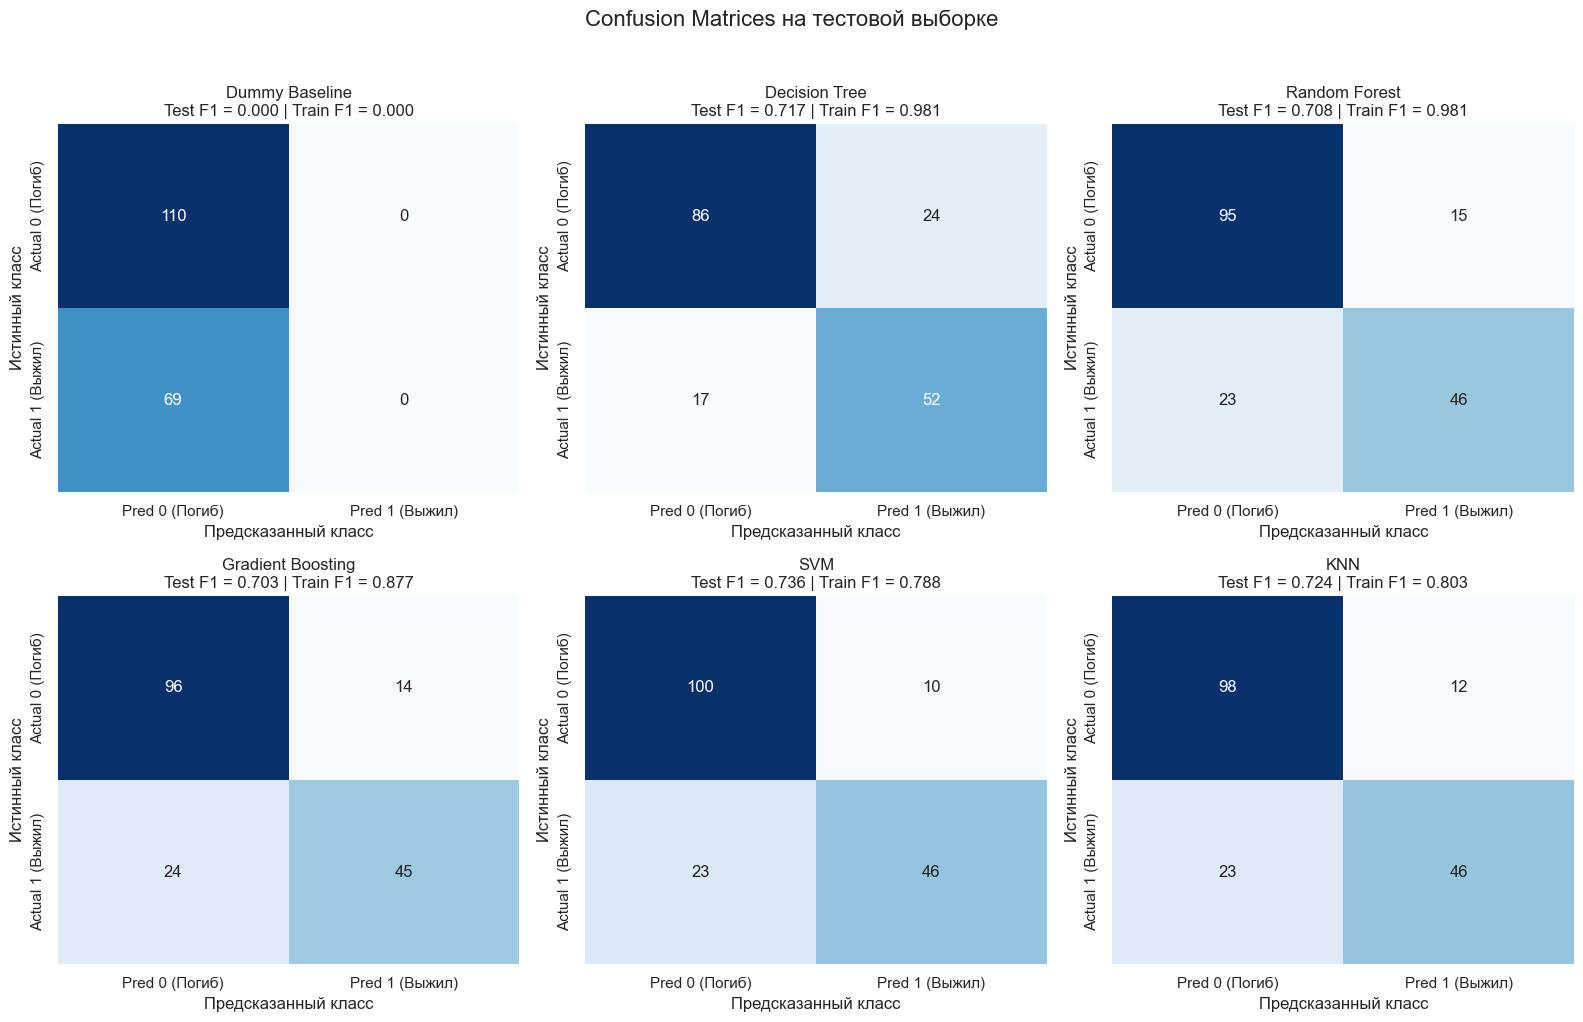

,Model,Accuracy,Precision,Recall,F1 (Test),F1 (Train),F1 (CV 5-fold),Pass (F1 > 0.70)
4,SVM,0.8156,0.8214,0.6667,0.7360,0.7880,0.7421,Да
5,KNN,0.8045,0.7931,0.6667,0.7244,0.8031,0.7359,Да
1,Decision Tree,0.7709,0.6842,0.7536,0.7172,0.9814,0.7117,Да
2,Random Forest,0.7877,0.7541,0.6667,0.7077,0.9814,0.7405,Да
3,Gradient Boosting,0.7877,0.7627,0.6522,0.7031,0.8769,0.7511,Да
0,Dummy Baseline,0.6145,0.0000,0.0000,0.0000,0.0000,0.0000,Нет


In [31]:
X = df.drop(columns=["Survived"])
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "SVM": SVC(kernel="rbf", C=1.0, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}


results = []
trained_pipelines = {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    pipe = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    
    pipe.fit(X_train, y_train)
    trained_pipelines[name] = pipe
    
    y_train_pred = pipe.predict(X_train)
    y_test_pred = pipe.predict(X_test)
    
    cv_f1 = cross_val_score(pipe, X_train, y_train, cv=skf, scoring='f1').mean()
    
    acc = accuracy_score(y_test, y_test_pred)
    prec = precision_score(y_test, y_test_pred, zero_division=0)
    rec = recall_score(y_test, y_test_pred, zero_division=0)
    f1_test = f1_score(y_test, y_test_pred, zero_division=0)
    f1_train = f1_score(y_train, y_train_pred, zero_division=0)
    
    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1 (Test)": f1_test,
        "F1 (Train)": f1_train,
        "F1 (CV 5-fold)": cv_f1,
        "Pass (F1 > 0.70)": "Да" if f1_test > 0.70 else "Нет"
    })
    
    cm = confusion_matrix(y_test, y_test_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[idx],
        xticklabels=["Pred 0 (Погиб)", "Pred 1 (Выжил)"],
        yticklabels=["Actual 0 (Погиб)", "Actual 1 (Выжил)"]
    )
    axes[idx].set_title(f"{name}\nTest F1 = {f1_test:.3f} | Train F1 = {f1_train:.3f}")
    axes[idx].set_ylabel("Истинный класс")
    axes[idx].set_xlabel("Предсказанный класс")

plt.suptitle("Confusion Matrices на тестовой выборке", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

leaderboard_df = pd.DataFrame(results).sort_values(by="F1 (Test)", ascending=False)
display(leaderboard_df.round(4))

### Анализ метрик, матриц ошибок (Confusion Matrices) и сравнение моделей:

1. **Преодоление порога качества ($F1 > 0.70$):**
   * `Dummy Baseline` всегда предсказывает наиболее частый класс (`0` - погиб), поэтому у него `Accuracy = 0.6145`, но для целевого класса `Survived = 1` метрики равны нулю (`Precision = 0`, `Recall = 0`, `F1 = 0.00`). Это наглядно показывает, почему `Accuracy` не подходит для несбалансированных выборок.
   * **Все 5 остальных моделей успешно прошли порог $F1 > 0.70$ на тестовой выборке:** лидирует `SVM` (`F1 = 0.7360`, `Accuracy = 0.8156`), за ним следуют `KNN` (`F1 = 0.7244`), `Decision Tree` (`F1 = 0.7172`), `Random Forest` (`F1 = 0.7077`) и `Gradient Boosting` (`F1 = 0.7031` на тесте и лучший результат `0.7511` на кросс-валидации).

2. **Различие между ошибками False Positive (FP) и False Negative (FN):**
   * **False Positive (FP, верхний правый угол матрицы):** модель предсказала, что пассажир выжил (`1`), но в реальности он погиб (`0`).
   * **False Negative (FN, нижний левый угол матрицы):** модель предсказала гибель (`0`), хотя пассажир на самом деле спасся (`1`).
   * У большинства моделей (SVM, KNN, Random Forest, Gradient Boosting) `Precision` (0.75–0.82) заметно выше `Recall` (0.65–0.67). По матрицам ошибок видно, что модели чаще совершают ошибки **False Negative** (порядка 23–24 ошибок против 10–15 ошибок FP). Поскольку погибших в выборке большинство (61.6%), алгоритмы более консервативны при назначении класса `1`.

3. **Анализ переобучения и сравнение алгоритмов:**
   * **Decision Tree:** наблюдается **сильное переобучение (overfitting)**. На обучающей выборке дерево без ограничения глубины практически заучило данные наизусть (`F1 Train = 0.9814`), тогда как на тесте и кросс-валидации качество падает до `0.7172` и `0.7117` (разрыв около 27%).
   * **Random Forest:** также имеет высокий показатель на трейне (`F1 Train = 0.9814`), но за счет усреднения ответов 100 независимых деревьев дает гораздо более высокую точность на кросс-валидации (`F1 CV = 0.7405`).
   * **Gradient Boosting:** строит неглубокие деревья последовательно, исправляя ошибки предыдущих шагов. Благодаря этому переобучение выражено значительно слабее (`F1 Train = 0.8769`), а на 5-фолдовой кросс-валидации бустинг показывает наивысший результат среди всех алгоритмов (`F1 CV = 0.7511`).
   * **SVM и KNN:** за счет правильного масштабирования признаков (`StandardScaler`) показали наименьший разрыв между `Train` (`0.788–0.803`) и `Test` (`0.724–0.736`), построив гладкую разделяющую границу без заучивания единичных шумовых объектов.

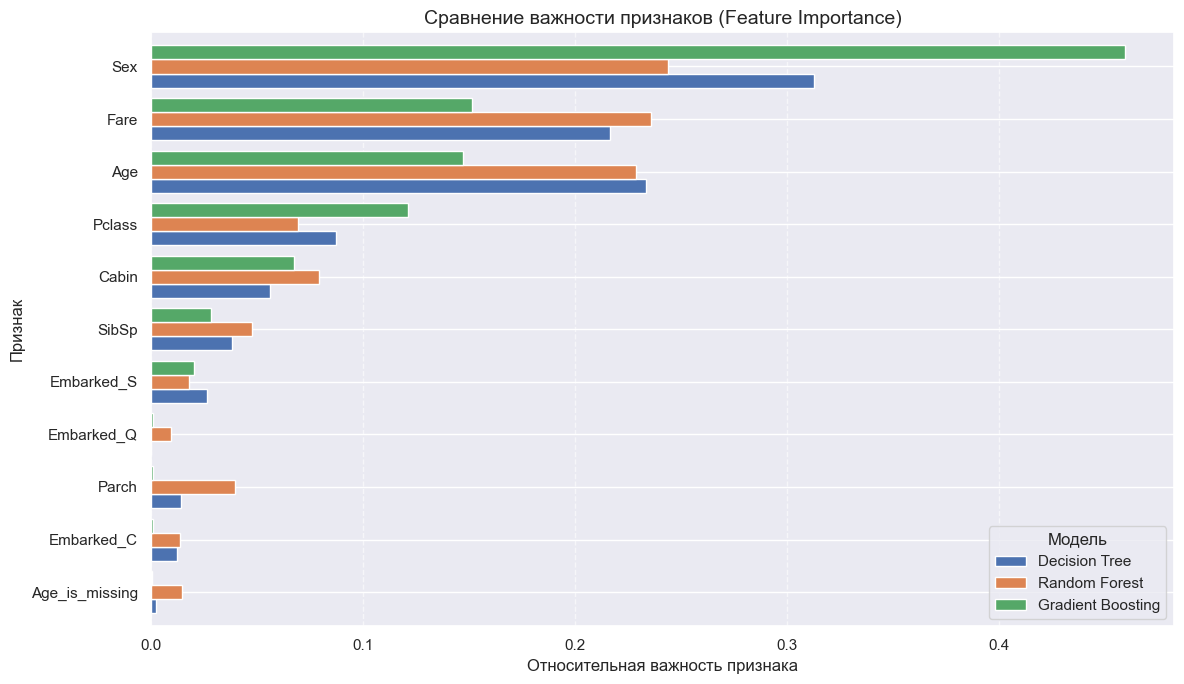

In [17]:
ohe_categories = (
    trained_pipelines["Gradient Boosting"] #берём любой, препроцессор у всех одинаковый
    .named_steps['preprocessor']
    .named_steps['column_processing']
    .named_transformers_['cat']
    .named_steps['onehot']
    .get_feature_names_out(categorical_features)
)
all_feature_names = numeric_features + list(ohe_categories)

tree_models = ["Decision Tree", "Random Forest", "Gradient Boosting"]
fi_data = {}

for name in tree_models:
    clf = trained_pipelines[name].named_steps['classifier']
    fi_data[name] = clf.feature_importances_

fi_df = pd.DataFrame(fi_data, index=all_feature_names)
fi_df = fi_df.sort_values(by="Gradient Boosting", ascending=True)

ax = fi_df.plot(kind="barh", figsize=(12, 7), width=0.8)
plt.title("Сравнение важности признаков (Feature Importance)", fontsize=14)
plt.xlabel("Относительная важность признака")
plt.ylabel("Признак")
plt.grid(axis='x', linestyle='--', alpha=0.6)
plt.legend(title="Модель")
plt.tight_layout()
plt.show()

### Важность признаков
для Decision Tree, Random Forest и Gradient Boosting: как видно из гистограммы - наиболее важный признак у всех трёх моделей - `Sex`.

In [18]:
best_model_name = leaderboard_df.iloc[0]["Model"]
best_pipe = trained_pipelines[best_model_name]

test_analysis = X_test.copy()
test_analysis["Actual_Survived"] = y_test
test_analysis["Pred_Survived"] = best_pipe.predict(X_test)

fp_cases = test_analysis[(test_analysis["Actual_Survived"] == 0) & (test_analysis["Pred_Survived"] == 1)]
fn_cases = test_analysis[(test_analysis["Actual_Survived"] == 1) & (test_analysis["Pred_Survived"] == 0)]

print(f"Лучшая модель: {best_model_name}")
print(f"Количество ошибок False Positive (ложно спасли): {len(fp_cases)}")
print(f"Количество ошибок False Negative (не заметили выжившего): {len(fn_cases)}\n")

print("Примеры False Positive:")
display(fp_cases[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin"]].head(5))

print("\nПримеры False Negative:")
display(fn_cases[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Cabin"]].head(5))


print("Распределение ошибок по полу и классу билета (Pclass x Sex):")
error_groups = test_analysis[test_analysis["Actual_Survived"] != test_analysis["Pred_Survived"]].groupby(["Pclass", "Sex", "Actual_Survived", "Pred_Survived"]).size()
display(error_groups.to_frame(name="Count"))

Лучшая модель: SVM
Количество ошибок False Positive (ложно спасли): 10
Количество ошибок False Negative (не заметили выжившего): 23

Примеры False Positive:


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin
27,1,male,19.0,3,2,263.0000,C23 C25 C27
297,1,female,2.0,1,2,151.5500,C22 C26
564,3,female,NaN,0,0,8.0500,NaN
502,3,female,NaN,0,0,7.6292,NaN
578,3,female,NaN,1,0,14.4583,NaN



Примеры False Negative:


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin
553,3,male,22.0,0,0,7.225,NaN
559,3,female,36.0,1,0,17.400,NaN
216,3,female,27.0,0,0,7.925,NaN
279,3,female,35.0,1,1,20.250,NaN
712,1,male,48.0,1,0,52.000,C126


Распределение ошибок по полу и классу билета (Pclass x Sex):


Count
Pclass Sex    Actual_Survived Pred_Survived       
1      female 0               1                  1
       male   0               1                  2
              1               0                  8
2      female 0               1                  1
       male   1               0                  2
3      female 0               1                  6
              1               0                  4
       male   1               0                  9

### Выводы по анализу ошибок лучшей модели (`SVM`):
1. **Какие типы ошибок встречаются чаще:**
   * Модель `SVM` на тестовой выборке (179 пассажиров) совершила **33 ошибки**: **10 ошибок False Positive** и **23 ошибки False Negative**. Ошибки типа **False Negative** (пропуск выжившего) встречаются более чем в 2 раза чаще, что также можно объяснить меньшим количеством объектов "выжил" в обучающей выборке.
2. **Для каких групп пассажиров модель ошибается наиболее заметно и почему:**
   * **Ошибки False Positive (10 человек):** в большинстве приходятся на **женщин из 3-го класса** (6 объектов).
   * **Ошибки False Negative (23 человека):** в основном это **взрослые мужчины из 1-го и 3-го классов**, которые статистически имели крайне низкий шанс выжить (поэтому модель присвоила им класс `0`), но спаслись благодаря случайным обстоятельствам (например, были подняты из воды складными шлюпками или попали в первые полупустые шлюпки).
3. **Проверка на утечку данных и идентификаторы:**
   * Идентифицирующие конкретных людей признаки (`PassengerId`, `Name`, `Ticket`) были полностью исключены из пайплайна (`remainder='drop'` в `ColumnTransformer`), поэтому высокое качество моделей обусловлено исключительно реальными социально-демографическими признаками, а не запоминанием отдельных объектов.